In [2]:
import os
import pandas as pd

os.chdir ('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\GBIF')

# Remove overlapping datasets (OBIS and GBIF)

In [10]:
gbif_path = os.path.join(os.getcwd(), "datasets_GBIF.parquet")
obis_path = os.path.join("..", "OBIS", "datasets_OBIS.parquet")

gbif_df = pd.read_parquet(gbif_path)
obis_df = pd.read_parquet(obis_path)

# Align OBIS column names with GBIF
obis_df = obis_df.rename(columns={
    "id": "alternateIdentifier",
    "published": "pubDate",
    "intellectualrights": "intellectualRights"
})

# Collapse embedded newlines and repeated whitespace in text fields
for frame in (gbif_df, obis_df):
    text_columns = frame.select_dtypes(include=["object", "string"]).columns
    for column in text_columns:
        frame[column] = (
            frame[column]
            .astype("string")
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

# Mark the source dataset for each row
gbif_df["source"] = "GBIF"
obis_df["source"] = "OBIS"

# Drop GBIF-only column if present
gbif_df = gbif_df.drop(columns=["licenseName"], errors="ignore")

# Merge by stacking rows, keeping all columns from both files
merged_df = pd.concat([gbif_df, obis_df], ignore_index=True, sort=False)

output_path = os.path.join(os.getcwd(), "datasets_GBIF_OBIS.parquet")
merged_df.to_parquet(output_path, index=False)

print(f"Saved: {output_path}")

Saved: C:\Users\hamod4691\Code\arctic-benthic-biodiversity\GBIF\datasets_GBIF_OBIS.parquet


In [11]:
df = pd.read_parquet("datasets_GBIF_OBIS.parquet")
df

,title,abstract,intellectualRights,url,citation,alternateIdentifier,pubDate,source
0,Bivalvia distribution data from: Deep-sea faun...,An annotated check-list is given of Bivalvia s...,This work is licensed under a Creative Commons...,https://emodnet.ec.europa.eu/geonetwork/srv/en...,"Janssen, R.; Krylova, E.M.; (2015). Bivalvia d...",0044f3b8-8305-47c6-b96d-a351a94ace74,2025-09-17,GBIF
1,Field Museum of Natural History (Zoology) Inve...,Building on acquisitions since the Museum’s fo...,"To the extent possible under law, the publishe...",http://fieldmuseum.org/explore/department/zool...,"Grant S, Webbink K, D'Angelo J (2026). Field M...",005eb8d8-ed94-41be-89cf-e3115a9058e4,2026-03-19,GBIF
2,Canadian Museum of Nature Parasite Collection,The Canadian Museum of Nature&#39;s Parasite C...,This work is licensed under a Creative Commons...,https://nature.ca/en/our-science/collections/;...,"Gagnon J, Blades R (2026). Canadian Museum of ...",00ed18ea-4993-4809-a656-62363baa4808,2026-04-05,GBIF
3,"Plankton community in Multinet (300µm), Tara O...",Tara expeditions (2009-2013) sampled the world...,This work is licensed under a Creative Commons...,https://ecotaxa.obs-vlfr.fr/api/collections/by...,Flanders Marine Institute: Plankton community ...,01883038-5ec6-4768-9d5b-8b6d56c314c0,2024-11-25,GBIF
4,A comprehensive checklist of earthworm species...,This dataset contains the digitized treatments...,"To the extent possible under law, the publishe...",https://tb.plazi.org/GgServer/summary/494B0149...,"Nguyen T T, Nguyen A D, Tran B T T, Blakemore ...",01995ca4-7d04-4402-b21a-926957b1a391,2016-12-31,GBIF
...,...,...,...,...,...,...,...,...
765,Invertebrate collection of the Seto Marine Bio...,<p>Invertebrate collection deposited in the Se...,This work is licensed under a Creative Commons...,https://www.godac.jamstec.go.jp/ipt/resource?r...,"National Museum of Nature and Science, Japan (...",6e5e5df0-1312-4c75-abff-644e9ade33df,2026-04-24T07:27:44.000Z,OBIS
766,uncultured prokaryote Targeted loci environmental,This study sequenced bacterial 16S ribosomal D...,This work is licensed under a Creative Commons...,https://hosted-datasets.gbif.org/mgnify/MGYS00...,<NA>,98154e56-6f2f-4656-b4ea-4f87f95bfaba,2022-09-20T12:42:00.000Z,OBIS
767,Type localities and distribution records of Pr...,Overview of world wide distributions and type ...,This work is licensed under a Creative Commons...,http://ipt.vliz.be/eurobis/resource?r=distribu...,Martens P.; Coomans A.; Schockaert E.; Laborat...,9fe2e775-30d6-4779-9d8c-d31a1ad31fae,2025-09-17T08:37:31.000Z,OBIS
768,Biogeographic distribution of Antarctic and su...,A comprehensive literature search was carried ...,This work is licensed under a Creative Commons...,https://ipt.biodiversity.aq/resource?r=antarct...,Southern Ocean Cumacea records by U. Muellenha...,b96a4245-b4a9-4505-a37e-2f076ad42b00,2019-03-19T14:46:17.000Z,OBIS


In [12]:
print(df.columns.tolist())
print(df["source"].value_counts(dropna=False))

['title', 'abstract', 'intellectualRights', 'url', 'citation', 'alternateIdentifier', 'pubDate', 'source']
source
GBIF    465
OBIS    305
Name: count, dtype: int64


In [13]:
# identify all rows whose title appears more than once (case-insensitive)
title_norm = df["title"].astype("string").str.lower().str.strip()
dup_mask = title_norm.duplicated(keep=False)

duplicate_datasets = df[dup_mask].copy()

# save with all columns
dup_path = os.path.join(os.getcwd(), "duplicate_datasets.parquet")
duplicate_datasets.to_parquet(dup_path, index=False)

print(f"Saved duplicates: {dup_path} (rows: {len(duplicate_datasets)})")

Saved duplicates: C:\Users\hamod4691\Code\arctic-benthic-biodiversity\GBIF\duplicate_datasets.parquet (rows: 308)


In [14]:
# remove only GBIF rows whose title also exists in OBIS, keeping OBIS as the priority source
title_norm = df["title"].astype("string").str.lower().str.strip()
obis_titles = set(title_norm[df["source"] == "OBIS"].dropna())
before = len(df)
mask_to_drop = (df["source"] == "GBIF") & title_norm.isin(obis_titles)
removed = int(mask_to_drop.sum())
df = df[~mask_to_drop].copy()
df.to_parquet(output_path, index=False)
after = len(df)
print(f"Before: {before}, After: {after}, Removed GBIF rows duplicated in OBIS: {removed}, Saved: {output_path}")

Before: 770, After: 617, Removed GBIF rows duplicated in OBIS: 153, Saved: C:\Users\hamod4691\Code\arctic-benthic-biodiversity\GBIF\datasets_GBIF_OBIS.parquet


In [15]:
gbif_titles = set(
    df.loc[df["source"] == "GBIF", "title"]
    .astype("string")
    .str.lower()
    .str.strip()
    .dropna()
)
obis_titles = set(
    df.loc[df["source"] == "OBIS", "title"]
    .astype("string")
    .str.lower()
    .str.strip()
    .dropna()
)
overlap = gbif_titles & obis_titles
print(f"Shared titles between GBIF and OBIS after filtering: {len(overlap)}")
if overlap:
    print(sorted(list(overlap))[:10])

Shared titles between GBIF and OBIS after filtering: 0


# Remove overlapping records (OBIS and GBIF)

In [16]:
merged_gbif_path = os.path.join(os.getcwd(), "merged_GBIF.parquet")
filtered_merged_gbif_path = os.path.join(os.getcwd(), "merged_GBIF.parquet")

# Recompute the GBIF dataset identifiers that overlapped with OBIS
gbif_title_norm = gbif_df["title"].astype("string").str.lower().str.strip()
removed_dataset_keys = set(
    gbif_df.loc[gbif_title_norm.isin(obis_titles), "alternateIdentifier"]
    .dropna()
    .astype(str)
)

merged_gbif_df = pd.read_parquet(merged_gbif_path)

before_records = len(merged_gbif_df)
mask_keep = ~merged_gbif_df["datasetKey"].astype("string").isin(removed_dataset_keys)
merged_gbif_df = merged_gbif_df[mask_keep].copy()
after_records = len(merged_gbif_df)

merged_gbif_df.to_parquet(filtered_merged_gbif_path, index=False)

print(f"Removed datasets: {len(removed_dataset_keys)}")
print(f"Records before: {before_records}, after: {after_records}")
print(f"Saved: {filtered_merged_gbif_path}")

Removed datasets: 153
Records before: 2588475, after: 2588475
Saved: C:\Users\hamod4691\Code\arctic-benthic-biodiversity\GBIF\merged_GBIF.parquet


# Prepare for merging

In [17]:
merged_GBIF = pd.read_parquet("merged_GBIF.parquet")
column_coverage_GBIF = pd.DataFrame({
    "column": merged_GBIF.columns,
    "non_null_count": merged_GBIF.notna().sum().values,
    "total_rows": len(merged_GBIF),
})

column_coverage_GBIF["coverage_pct"] = (
    column_coverage_GBIF["non_null_count"] / column_coverage_GBIF["total_rows"] * 100
)

column_coverage_GBIF = column_coverage_GBIF.sort_values(
    by=["coverage_pct", "non_null_count"], ascending=False
)

column_coverage_GBIF.to_csv("column_coverage_GBIF.csv", index=False)

column_coverage_GBIF.head()

,column,non_null_count,total_rows,coverage_pct
0,gbifID,2588475,2588475,100.0
1,accessRights,2588475,2588475,100.0
2,bibliographicCitation,2588475,2588475,100.0
3,language,2588475,2588475,100.0
4,license,2588475,2588475,100.0


In [3]:
merged_GBIF = pd.read_parquet("merged_GBIF.parquet")

year_num = pd.to_numeric(merged_GBIF["year"], errors="coerce")
doy_num = pd.to_numeric(merged_GBIF["endDayOfYear"], errors="coerce")

def to_date(y, doy):
    if pd.isna(y) or pd.isna(doy):
        return pd.NA
    try:
        return (pd.Timestamp(int(y), 1, 1) + pd.Timedelta(days=int(doy) - 1)).strftime("%Y-%m-%d")
    except Exception:
        return pd.NA

merged_GBIF["endDate"] = [
    to_date(y, d) for y, d in zip(year_num, doy_num)
]

merged_GBIF.to_parquet("merged_GBIF.parquet", index=False)

print("Added endDate column and saved merged_GBIF.parquet.")
print(f"Non-null endDate values: {merged_GBIF['endDate'].notna().sum():,}")

Added endDate column and saved merged_GBIF.parquet.
Non-null endDate values: 1,682,252


In [4]:
gbif = pd.read_parquet("merged_GBIF.parquet")

column_map = {
    "sourceID": "gbifID",
    "verbatimID": "occurrenceID",
    "datasetKey": "datasetKey",
    "issue": "issue",
    "decimalLatitudeStart": "decimalLatitude",
    "decimalLongitudeStart": "decimalLongitude",
    "footprintWKT": "footprintWKT",
    "coordinateUncertaintyInMeters": "coordinateUncertaintyInMeters",
    "hasGeospatialIssues": "hasGeospatialIssues",
    "depthA": "depth",
    "depthAccuracy": "depthAccuracy",
    "eventID": "eventID",
    "parentEventID": "parentEventID",
    "waterBody": "waterBody",
    "startDate": "eventDate",
    "endDate": "endDate",
    "year": "year",
    "eventRemarks": "eventRemarks",
    "verbatimScientificName": "verbatimScientificName",
    "acceptedScientificName": "acceptedScientificName",
    "identificationQualifier": "identificationQualifier",
    "lifeStage": "lifeStage",
    "sex": "sex",
    "taxonomicStatus": "taxonomicStatus",
    "taxonomicIssue": "taxonomicIssue",
    "taxonRank": "taxonRank",
    "phylum": "phylum",
    "class": "class",
    "order": "order",
    "family": "family",
    "genus": "genus",
    "individualCount": "individualCount",
    "basisOfRecord": "basisOfRecord",
    "gear": "samplingProtocol",
}

output_columns = [
    "ID",
    "sourceID",
    "verbatimID",
    "sourceDatabase",
    "datasetKey",
    "datasetTitle",
    "issue",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "decimalLatitudeStop",
    "decimalLongitudeStop",
    "footprintWKT",
    "coordinateUncertaintyInMeters",
    "hasGeospatialIssues",
    "depthA",
    "depthAType",
    "depthB",
    "depthBType",
    "depthAccuracy",
    "gebcoDepth",
    "eventID",
    "parentEventID",
    "waterBody",
    "largeMarineEcosystem",
    "locationID",
    "startDate",
    "endDate",
    "year",
    "eventRemarks",
    "verbatimScientificName",
    "acceptedScientificName",
    "identificationQualifier",
    "lifeStage",
    "sex",
    "taxonomicStatus",
    "taxonomicIssue",
    "taxonRank",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "specificEpithet",
    "validAuthority",
    "aphiaID",
    "individualCount",
    "samplingEffort",
    "percentCoverage",
    "biomass",
    "biomassUnit",
    "dryMass",
    "dynamicProperties",
    "basisOfRecord",
    "occurrenceRemarks",
    "gear",
    "gearCategory",
    "gearDescription",
    "gearDimensions",
    "meshSize",
    "sieveFraction",
    "sampleSizeValue",
    "sampleSizeUnit",
    "subsampleToSampleRatio",
    "subsampleSpatialLevel",
    "flagged", 
    "flaggedComment"
]

gbif_final = pd.DataFrame(index=gbif.index)
missing_sources = []

for col in output_columns:
    if col in column_map:
        src = column_map[col]
        if src in gbif.columns:
            gbif_final[col] = gbif[src]
        else:
            gbif_final[col] = pd.NA
            missing_sources.append(src)
    else:
        gbif_final[col] = pd.NA

gbif_final = gbif_final[output_columns]
gbif_final.to_parquet("gbif_final.parquet", index=False)

print(f"Saved gbif_final.parquet with {len(gbif_final):,} rows and {len(gbif_final.columns)} columns.")
if missing_sources:
    print("Missing source columns in gbif:", sorted(set(missing_sources)))

Saved gbif_final.parquet with 2,588,475 rows and 66 columns.


In [5]:
gbif_final = pd.read_parquet("gbif_final.parquet")
gbif_final["sourceDatabase"] = "GBIF"
gbif_final.to_parquet("gbif_final.parquet", index=False)
print("Added sourceDatabase column with value 'GBIF' and saved gbif_final.parquet.")

Added sourceDatabase column with value 'GBIF' and saved gbif_final.parquet.


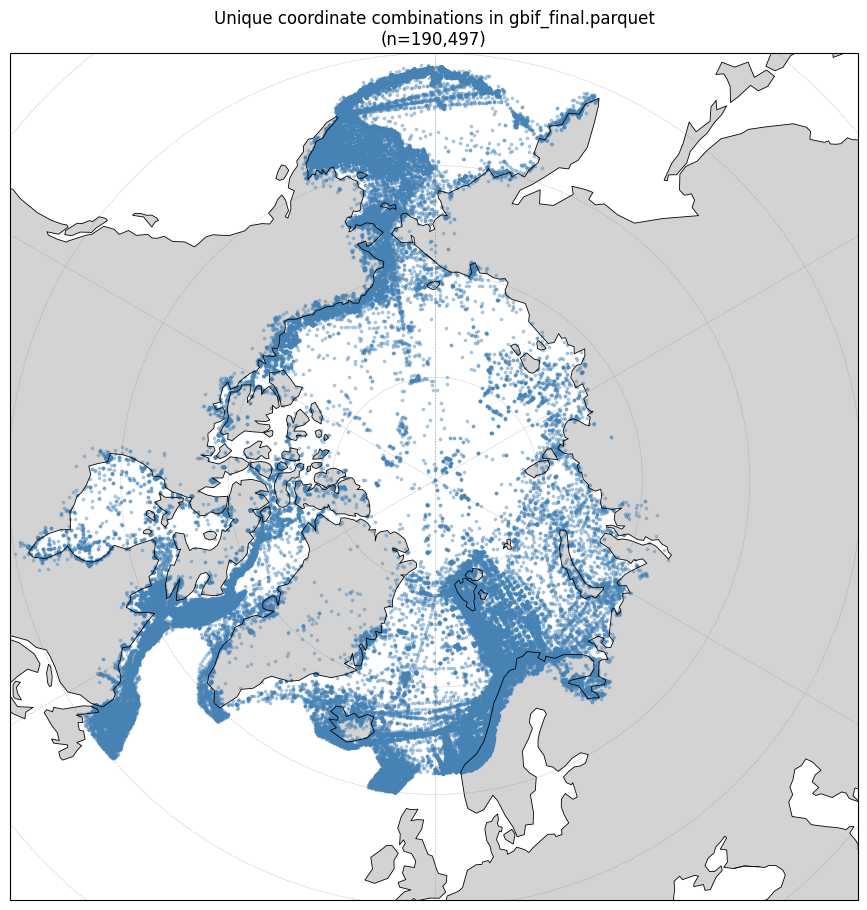

In [33]:
import pandas as pd

import matplotlib.pyplot as plt

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
except ImportError as e:
    raise ImportError("cartopy is required for polar stereographic mapping.") from e

# Load data
gbif_final = pd.read_parquet("gbif_final.parquet")

# Use the coordinate columns from gbif_final
lat_col = "decimalLatitudeStart"
lon_col = "decimalLongitudeStart"

# Keep unique coordinate pairs only
coords = (
    gbif_final[[lon_col, lat_col]]
    .dropna()
    .assign(
        **{
            lon_col: lambda d: d[lon_col].round(6),
            lat_col: lambda d: d[lat_col].round(6),
        }
    )
    .drop_duplicates()
)

# Optional: focus on the Arctic
coords = coords[coords[lat_col] >= 30]

fig = plt.figure(figsize=(11, 11))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.OCEAN, facecolor="white")
ax.coastlines(linewidth=0.6)
ax.gridlines(draw_labels=False, linewidth=0.4, color="gray", alpha=0.5, linestyle="--")

ax.scatter(
    coords[lon_col],
    coords[lat_col],
    s=3,
    alpha=0.35,
    color="steelblue",
    transform=ccrs.PlateCarree(),
)

ax.set_title(f"Unique coordinate combinations in gbif_final.parquet\n(n={len(coords):,})")
plt.show()